In [1]:
import tensorflow as tf
tf.config.set_visible_devices([], 'GPU')

## APRENDIZAJE FEDERADO.

El aprendizaje federado consiste en entrenar un modelo localmente con un subconjunto de datos, para después computar un modelo global (idéntico) que será desplegado como un servicio.

Para simular una situación de aprendizaje federado, usaremos la bien-conocida base de datos MNIST para interpretar número escritos a mano, y la dividiremos en cinco partes (en su caso, será en cuantos miembros de su equipo tengan).

Same seed initialization (p.4):
https://proceedings.mlr.press/v54/mcmahan17a/mcmahan17a.pdf

A same seed initialization was used, as when each individual client parts from a random step, the follow up models perrform poorly in contrast when initializing them into the same seed/ initial weight

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
(train_images, train_labels), (test_images, test_labels) = (tf.keras.datasets.mnist.load_data())

x_test = np.expand_dims(test_images.astype("float32") / 255.0,-1)

y_test = test_labels

# Actualiza segun id que tocó
x_local = np.load("x_client_0.npy")
y_local = np.load("y_client_0.npy")

In [4]:
from sklearn.metrics import classification_report
def train_and_verify(local_model, x_local, y_local, epochs, x_test, y_test, save_name):

    print("DEBUGGG")
    print(local_model)
    print(x_local.shape)
    print(y_local.shape)
    
    history = local_model.fit(x_local, y_local, epochs=epochs, validation_data=(x_test, y_test))
    y_pred = local_model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)
    print(classification_report(y_test, y_pred_classes))

    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

    local_model.save(save_name)

DEBUGGG
<Functional name=functional, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8613 - loss: 0.4927 - val_accuracy: 0.9210 - val_loss: 0.2738
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 739us/step - accuracy: 0.9315 - loss: 0.2332 - val_accuracy: 0.9414 - val_loss: 0.1967
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step - accuracy: 0.9495 - loss: 0.1726 - val_accuracy: 0.9384 - val_loss: 0.1987
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 747us/step - accuracy: 0.9605 - loss: 0.1370 - val_accuracy: 0.9468 - val_loss: 0.1742
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - accuracy: 0.9683 - loss: 0.1128 - val_accuracy: 0.9484 - val_loss: 0.1783
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step - accuracy: 0.9724 - loss: 0.0923 - val_accuracy: 0.9542 - val_loss: 0.1524
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 762us/step - accuracy: 0.9769 - loss: 0.0771 - val_accuracy: 0.9566 - val_loss: 0.1505
Epoch 8/15
469/

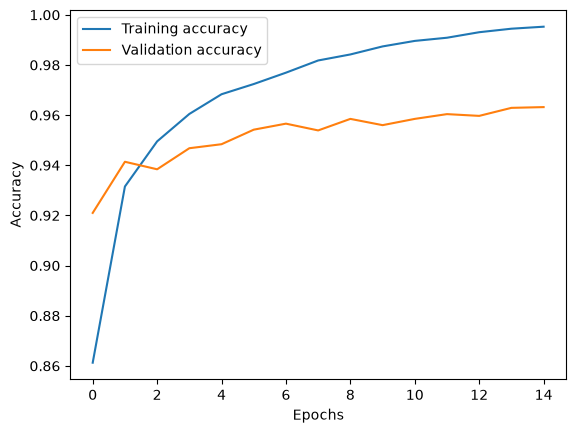

In [5]:
from model_2 import build

#initial_weights = global_model.get_weights()
local_model = build.build_model()
#local_model.set_weights(initial_weights)

train_and_verify(
    local_model,
    x_local,
    y_local,
    15,
    x_test,
    y_test,
    "lmodel_0.keras"
)

In [6]:
local_model = build.build_model()

print("INPUT:", local_model.input_shape)
print("OUTPUT:", local_model.output_shape)

local_model.summary()

INPUT: (None, 28, 28, 1)
OUTPUT: (None, 10)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)


Cliente 0
DEBUGGG
<Functional name=functional_2, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8652 - loss: 0.4649 - val_accuracy: 0.9039 - val_loss: 0.3144
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 957us/step - accuracy: 0.9316 - loss: 0.2319 - val_accuracy: 0.9344 - val_loss: 0.2177
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 769us/step - accuracy: 0.9499 - loss: 0.1742 - val_accuracy: 0.9459 - val_loss: 0.1854
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 754us/step - accuracy: 0.9608 - loss: 0.1371 - val_accuracy: 0.9501 - val_loss: 0.1700
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 738us/step - accuracy: 0.9669 - loss: 0.1116 - val_accuracy: 0.9550 - val_loss: 0.1571
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 741us/step - accuracy: 0.9732 - loss: 0.0932 - val_accuracy: 0.9558 - val_loss: 0.1507
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 738us/step - accuracy: 0.9761 - loss: 0.0793 - val_accuracy: 0.9578 - val_loss: 0.1454
Ep

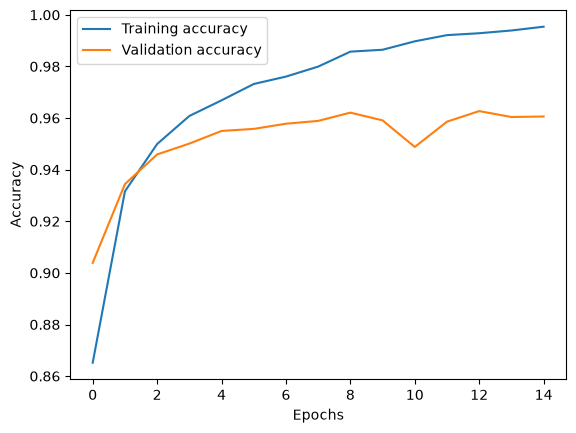


Cliente 1
DEBUGGG
<Functional name=functional_3, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 909us/step - accuracy: 0.8629 - loss: 0.4813 - val_accuracy: 0.9199 - val_loss: 0.2706
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step - accuracy: 0.9331 - loss: 0.2253 - val_accuracy: 0.9379 - val_loss: 0.2146
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 920us/step - accuracy: 0.9487 - loss: 0.1674 - val_accuracy: 0.9518 - val_loss: 0.1682
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 795us/step - accuracy: 0.9613 - loss: 0.1342 - val_accuracy: 0.9548 - val_loss: 0.1519
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 847us/step - accuracy: 0.9659 - loss: 0.1084 - val_accuracy: 0.9561 - val_loss: 0.1497
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 785us/step - accuracy: 0.9727 - loss: 0.0892 - val_accuracy: 0.9561 - val_loss: 0.1567
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9768 - loss: 0.0723 - val_accuracy: 0.9594 - val_loss: 0.1482
Ep

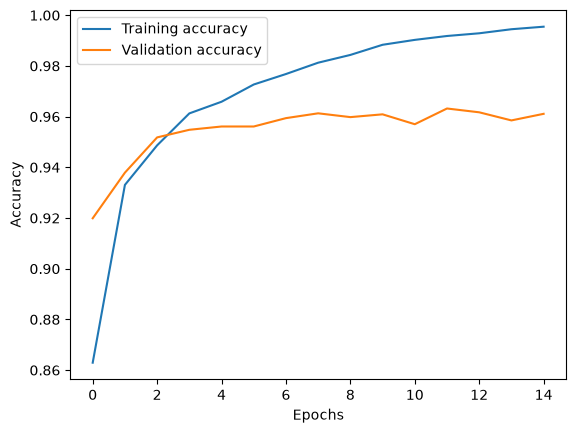


Cliente 2
DEBUGGG
<Functional name=functional_4, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 891us/step - accuracy: 0.8639 - loss: 0.4868 - val_accuracy: 0.9265 - val_loss: 0.2556
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 998us/step - accuracy: 0.9315 - loss: 0.2309 - val_accuracy: 0.9384 - val_loss: 0.2131
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 835us/step - accuracy: 0.9499 - loss: 0.1702 - val_accuracy: 0.9435 - val_loss: 0.1798
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step - accuracy: 0.9603 - loss: 0.1330 - val_accuracy: 0.9385 - val_loss: 0.2126
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 792us/step - accuracy: 0.9668 - loss: 0.1092 - val_accuracy: 0.9517 - val_loss: 0.1689
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 745us/step - accuracy: 0.9723 - loss: 0.0884 - val_accuracy: 0.9577 - val_loss: 0.1423
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - accuracy: 0.9781 - loss: 0.0724 - val_accuracy: 0.9569 - val_loss: 0.1531


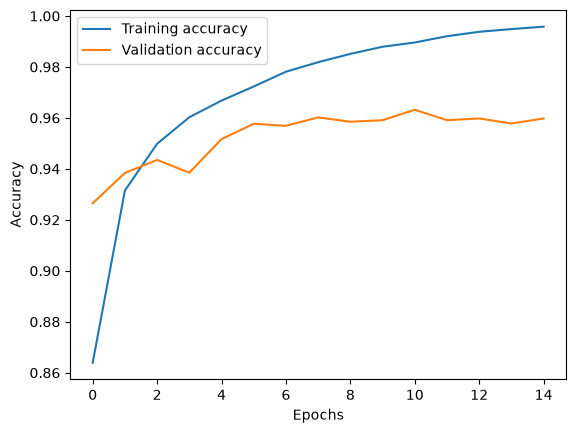


Cliente 3
DEBUGGG
<Functional name=functional_5, built=True>
(15000, 28, 28, 1)
(15000,)
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 898us/step - accuracy: 0.8599 - loss: 0.4919 - val_accuracy: 0.9233 - val_loss: 0.2679
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 994us/step - accuracy: 0.9266 - loss: 0.2455 - val_accuracy: 0.9385 - val_loss: 0.2044
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - accuracy: 0.9469 - loss: 0.1809 - val_accuracy: 0.9322 - val_loss: 0.2302
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step - accuracy: 0.9586 - loss: 0.1417 - val_accuracy: 0.9486 - val_loss: 0.1747
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 754us/step - accuracy: 0.9661 - loss: 0.1143 - val_accuracy: 0.9548 - val_loss: 0.1491
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 757us/step - accuracy: 0.9729 - loss: 0.0954 - val_accuracy: 0.9569 - val_loss: 0.1568
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 751us/step - accuracy: 0.9761 - loss: 0.0809 - val_accuracy: 0.9581 - val_loss: 0.1474


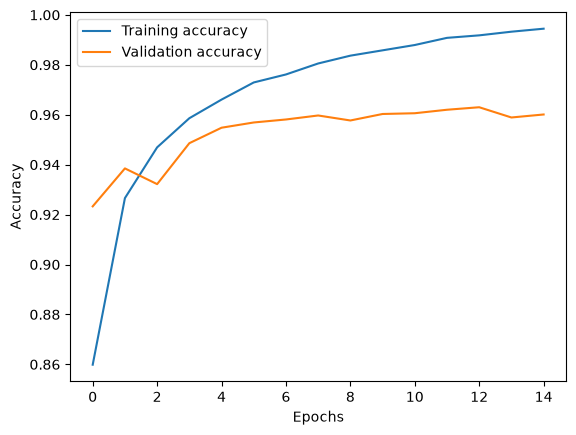

In [7]:
# Print todos los modelos locales entrenados
from model_2 import build

#global_model = build.build_model()

#initial_weights = global_model.get_weights()

for i in range(4):

    print(f"\nCliente {i}")

    x_local = np.load(f"x_client_{i}.npy")
    y_local = np.load(f"y_client_{i}.npy")

    local_model = build.build_model()
    local_model.set_weights(local_model.get_weights())

    train_and_verify(
        local_model,
        x_local,
        y_local,
        15,
        x_test,
        y_test,
        f"lmodel_{i}.keras"
    )

In [8]:
## Abrir los modelos:

import os
loaded_local_models = [tf.keras.models.load_model(f) for f in os.listdir(".") if f.startswith("lmodel_")]


for i in range(len(loaded_local_models)-1):
    assert loaded_local_models[i].summary() == loaded_local_models[i+1].summary(), "Models have different architectures"

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ digits (InputLayer)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,102 (430.09 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 55,052 (215.05 KB)

## Debug

In [9]:
local_weights = [x.get_weights() for x in loaded_local_models]
averaged_weights = [np.mean(np.array(weights), axis=0) for weights in zip(*local_weights)]

global_model = build.build_model()
global_model.set_weights(averaged_weights)

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = global_model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

global_model.save('global_model.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       980
           1       0.03      0.00      0.00      1135
           2       0.62      0.80      0.70      1032
           3       0.62      0.33      0.43      1010
           4       0.88      0.21      0.33       982
           5       0.13      0.99      0.23       892
           6       1.00      0.01      0.02       958
           7       0.28      0.01      0.01      1028
           8       0.47      0.36      0.41       974
           9       0.71      0.07      0.13      1009

    accuracy                           0.27     10000
   macro avg       0.47      0.28      0.23     10000
weighted avg       0.47      0.27      0.23     10000



/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/samanthabritoozuna/cloud_comp/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 612us/step - accuracy: 0.9203 - loss: 0.2736 - val_accuracy: 0.9565 - val_loss: 0.1443
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 566us/step - accuracy: 0.9615 - loss: 0.1290 - val_accuracy: 0.9550 - val_loss: 0.1485
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 538us/step - accuracy: 0.9709 - loss: 0.0987 - val_accuracy: 0.9694 - val_loss: 0.1064
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 551us/step - accuracy: 0.9761 - loss: 0.0798 - val_accuracy: 0.9731 - val_loss: 0.0914
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 575us/step - accuracy: 0.9793 - loss: 0.0695 - val_accuracy: 0.9720 - val_loss: 0.1010
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 565us/step - accuracy: 0.9819 - loss: 0.0605 - val_accuracy: 0.9775 - val_loss: 0.0929
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 541us/step - accuracy: 0.9840 - loss: 0.0534 - val_accuracy: 0.9764 - val_loss: 0.0914
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 568us/step - accuracy: 0.9861 -

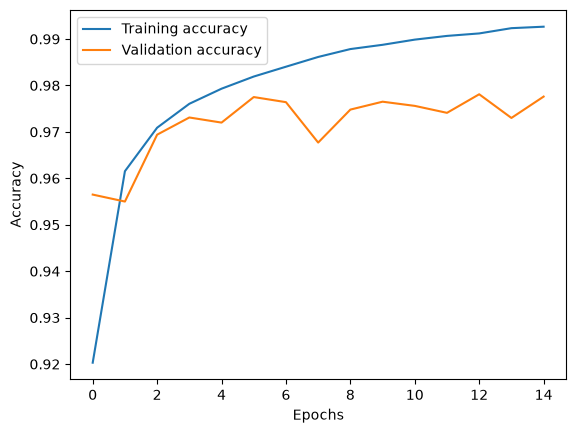

In [10]:
## VS A NORMAL GLOBLA MODEL TRAINED IN A SINGLE DEVICE:
train, test = tf.keras.datasets.mnist.load_data()

x_train, x_test = np.expand_dims(train[0] / 255.0, -1), np.expand_dims(test[0] / 255.0, -1)
y_train, y_test = train[1], test[1]

model = build.build_model()

history = model.fit(x_train, y_train, epochs=15, validation_data=(x_test, y_test))

from sklearn.metrics import classification_report
# Predict the classes for the test set
y_pred = model.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

# Optionally, plot training history
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Bibliography:

https://www.tensorflow.org/guide/keras/training_with_built_in_methods
